# 6 — An interacting trapped system with an exact g(x, x')

Notebook 3 checked the estimators on the free harmonic oscillator. There the particles
are independent, g(x, x') is flat, and a Gaussian envelope alone is already the exact
state. This notebook adds an interaction while keeping everything analytic: the
**Moshinsky model**, particles in a harmonic trap coupled by springs,

    H = sum_i ( -1/2 d^2/dx_i^2 + 1/2 x_i^2 ) + 1/2 w^2 sum_{i<j} (x_i - x_j)^2 .

`NN_OscillatorHamiltonian` couples nearest neighbours on a ring. For N = 3 the ring
contains every pair, so it is exactly Moshinsky.

Same steps as notebook 3: exact state → check the estimators → train a `[16]` MLP →
compare g(x, x') and S(k, k') with the analytic matrices.

In [11]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import warnings
warnings.filterwarnings("ignore")

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import flax.linen as nn
from scipy.linalg import sqrtm

# not "raise": the library MLP broadcasts its bias (batch, H) + (H,)

from qvarnet.analysis.estimators import TrainedWavefunction
from qvarnet.physics.hamiltonian.continuous import NN_OscillatorHamiltonian

## The exact solution of any quadratic Hamiltonian

Write the potential as V = 1/2 x^T K x. Rotating to normal modes gives independent
oscillators with frequencies sqrt(eig K), so (hbar = m = 1)

- psi_0 ∝ exp(-1/2 x^T sqrt(K) x),  E_0 = 1/2 Tr sqrt(K)
- |psi_0|^2 is a Gaussian with covariance Sigma = (2 sqrt(K))^-1.

We take K as the Hessian of the Hamiltonian's own `potential_energy`, so the reference
cannot silently disagree with what is being trained.

For N = 3 and w = 1: K = I + w^2 (3I - J) has eigenvalues 1 (the centre of mass, which
does not feel the springs) and 4 (twice), so E_0 = (1 + 2 + 2)/2 = 2.5.

In [12]:
n_particles = 3
ham = NN_OscillatorHamiltonian(omega_trap=1.0, omega_interaction=1.0, with_pbc=True)

V = lambda x: ham.potential_energy(x[None, :])[0]
K = np.asarray(jax.hessian(V)(jnp.zeros(n_particles)))
sqrtK = np.real(sqrtm(K))
Sigma = np.linalg.inv(2 * sqrtK)
E0 = 0.5 * np.trace(sqrtK)

print("K =\n", K)
print("eig K:", np.linalg.eigvalsh(K), "   E_0 =", E0)
print("Sigma =\n", Sigma.round(4))

K =
 [[ 3. -1. -1.]
 [-1.  3. -1.]
 [-1. -1.  3.]]
eig K: [1. 4. 4.]    E_0 = 2.5
Sigma =
 [[0.3333 0.0833 0.0833]
 [0.0833 0.3333 0.0833]
 [0.0833 0.0833 0.3333]]


### Analytic g(x, x') and S(k, k')

Everything follows from Sigma. The pair density is a sum of 2-D Gaussian marginals over
ordered pairs i != j, and the density is a sum of 1-D marginals:

    rho_2(x, x') = sum_{i != j} N2([x, x']; Sigma_ii, Sigma_jj, Sigma_ij),
    rho(x)       = sum_i N1(x; Sigma_ii),     g = rho_2 / (rho rho).

For S(k, k') = (<rho_k rho_k'*> - <rho_k><rho_k'>*) / N, Gaussian characteristic
functions give

    <exp(i k x_i - i k' x_j)> = exp(-1/2 (k^2 Sigma_ii + k'^2 Sigma_jj - 2 k k' Sigma_ij)).

Positive Sigma_ij means the springs pull the particles together. Expect bunching:
g > 1 near the diagonal x = x', and g < 1 for particles on opposite sides of the trap.

In [13]:
def g_exact(grid, Sigma):
    X, Y = np.meshgrid(grid, grid, indexing="ij")
    N = Sigma.shape[0]
    rho = sum(np.exp(-grid**2 / (2 * Sigma[i, i])) / np.sqrt(2 * np.pi * Sigma[i, i]) for i in range(N))
    rho2 = np.zeros_like(X)
    for i in range(N):
        for j in range(N):
            if i == j:
                continue
            C = np.array([[Sigma[i, i], Sigma[i, j]], [Sigma[j, i], Sigma[j, j]]])
            Ci = np.linalg.inv(C)
            q = Ci[0, 0] * X**2 + 2 * Ci[0, 1] * X * Y + Ci[1, 1] * Y**2
            rho2 += np.exp(-q / 2) / (2 * np.pi * np.sqrt(np.linalg.det(C)))
    return rho2 / np.outer(rho, rho)


def S_exact(k, Sigma):
    N = Sigma.shape[0]
    d = np.diag(Sigma)
    kk, kp = k[:, None], k[None, :]
    corr = sum(
        np.exp(-0.5 * (kk**2 * d[i] + kp**2 * d[j] - 2 * kk * kp * Sigma[i, j]))
        for i in range(N) for j in range(N)
    )
    mean = sum(np.exp(-0.5 * k**2 * d[i]) for i in range(N))
    return (corr - np.outer(mean, mean)) / N


grid = np.linspace(-2.5, 2.5, 50)
kk = np.linspace(0.1, 6.0, 40)
G_ex, S_ex = g_exact(grid, Sigma), S_exact(kk, Sigma)
assert G_ex.shape == (50, 50) and S_ex.shape == (40, 40)

## Step 1 — the estimators on the exact state

As in notebook 3, the ansatz is just an `nn.Module` returning log|psi|, here the exact
one with no parameters. This checks the estimators *and* the formulas above before any
training is involved.

In [14]:
class ExactMoshinsky(nn.Module):
    sqrtK: tuple  # hashable, so the module stays a static dataclass

    @nn.compact
    def __call__(self, x):
        A = jnp.asarray(self.sqrtK)
        return -0.5 * jnp.sum((x @ A) * x, axis=-1, keepdims=True)


exact_model = ExactMoshinsky(tuple(map(tuple, sqrtK)))
exact_params = exact_model.init(jax.random.PRNGKey(0), jnp.ones((1, n_particles)))
wf_ex = TrainedWavefunction(exact_model, exact_params, n_particles=n_particles, n_dim=1, seed=0)
wf_ex.sample(n_chains=512, n_steps=1000, burn_in=100, thinning=4, step_size=0.8)

# the cheapest check: the sampled covariance must be Sigma
s = np.asarray(wf_ex.samples)
print("sampled covariance:\n", np.cov(s.T).round(4))
print("max |cov - Sigma| =", f"{np.max(np.abs(np.cov(s.T) - Sigma)):.4f}")

IAT: 6.99  mean ESS: 3153.3
sampled covariance:
 [[0.3324 0.0852 0.0841]
 [0.0852 0.3364 0.0845]
 [0.0841 0.0845 0.3333]]
max |cov - Sigma| = 0.0030


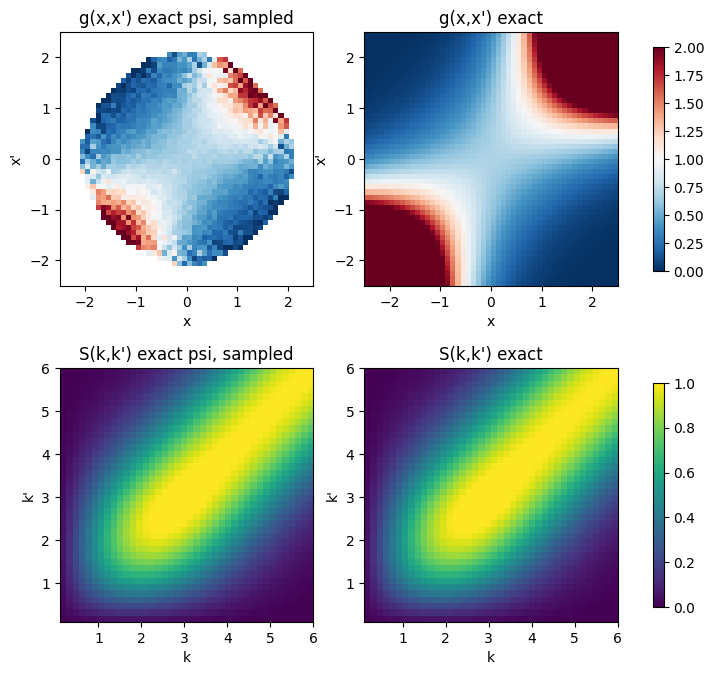

bulk |x|,|x'| < 1.5: max |g - exact| = nan, rms = nan
max |S - exact| = 0.006


In [15]:
def compare(wf, title):
    """g and S of ``wf`` next to the exact matrices; prints the bulk errors."""
    _, G = wf.pair_correlation_grid(grid)
    _, S = wf.structure_factor_matrix(k_values=kk)

    fig, ax = plt.subplots(2, 2, figsize=(9, 8))
    ext_g = [grid[0], grid[-1], grid[0], grid[-1]]
    ext_k = [kk[0], kk[-1], kk[0], kk[-1]]
    for a, m, t in [(ax[0, 0], G, f"g(x,x') {title}"), (ax[0, 1], G_ex, "g(x,x') exact")]:
        im = a.imshow(m.T, origin="lower", extent=ext_g, vmin=0.0, vmax=2.0, cmap="RdBu_r")
        a.set(xlabel="x", ylabel="x'", title=t)
    fig.colorbar(im, ax=ax[0], shrink=0.8)
    for a, m, t in [(ax[1, 0], S.real, f"S(k,k') {title}"), (ax[1, 1], S_ex, "S(k,k') exact")]:
        im = a.imshow(m.T, origin="lower", extent=ext_k, vmin=0, vmax=1, cmap="viridis")
        a.set(xlabel="k", ylabel="k'", title=t)
    fig.colorbar(im, ax=ax[1], shrink=0.8)
    plt.show()

    # the tails hold only a handful of pairs per bin, so judge g in the bulk
    bulk = np.abs(grid) < 1.5
    dg = (G - G_ex)[np.ix_(bulk, bulk)]
    print(f"bulk |x|,|x'| < 1.5: max |g - exact| = {np.max(np.abs(dg)):.3f}, rms = {np.sqrt(np.mean(dg**2)):.3f}")
    print(f"max |S - exact| = {np.max(np.abs(S - S_ex)):.3f}")


compare(wf_ex, "exact psi, sampled")

The colour scale is centred on g = 1 (uncorrelated): red is bunching, blue is
depletion. The particles cluster together, and a particle at x makes it unlikely to find
another at -x. Unlike the free case, S(k, k') is no longer 1 - exp(-k^2/2) on the
diagonal: the interaction suppresses long-wavelength density fluctuations of the
relative coordinates.

## Step 2 — train a `[16]` MLP

Use the same ansatz as notebook 3. The Gaussian envelope is a product over particles, so
it can only produce the diagonal of sqrt(K). The cross terms x_i x_j, which are the
interaction, must come from the network.

100%|██████████| 5000/5000 [00:34<00:00, 145.65it/s, E=2.5136, sigma_E=0.2821]


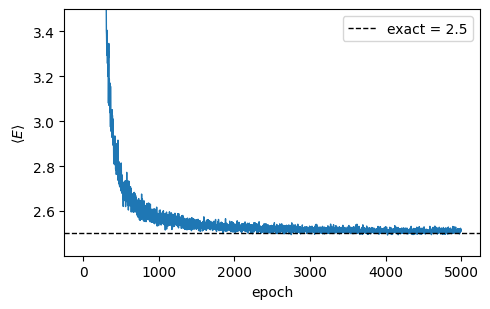

tail energy 2.50969   exact 2.5   tail sigma_E 0.2690


In [16]:
import tempfile
from qvarnet import VMC, SamplingConfig, TrainingConfig
from qvarnet.ansatz.compose import LogWavefunction
from qvarnet.ansatz.envelopes import GaussianEnvelope
from qvarnet.ansatz.mlp import MLP

psi = LogWavefunction(network=MLP(hidden=[16], output_dim=1), envelope=GaussianEnvelope())
n_epochs = 5000
result = VMC(
    shape=(2000, n_particles),
    model=psi,
    optimizer=optax.adam(optax.cosine_decay_schedule(5e-3, n_epochs, alpha=0.05)),
    hamiltonian=ham,
    training_config=TrainingConfig(
        n_epochs=n_epochs, rng_seed=0, checkpoint_path=tempfile.mkdtemp(),
        is_update_step_size=True, print_summary=False,
    ),
    sampler_params=SamplingConfig(
        step_size=0.5, chain_length=21, thermalization_steps=20, thinning_factor=1,
    ),
).run()

energy = np.asarray(result.history.get("energy"))
std = np.asarray(result.history.get("std"))
plt.figure(figsize=(5, 3.2))
plt.plot(energy, lw=1)
plt.axhline(E0, color="k", ls="--", lw=1, label=f"exact = {E0}")
plt.ylim(E0 - 0.1, E0 + 1.0); plt.xlabel("epoch"); plt.ylabel(r"$\langle E \rangle$")
plt.legend(); plt.tight_layout(); plt.show()
print(f"tail energy {energy[-100:].mean():.5f}   exact {E0}   tail sigma_E {std[-100:].mean():.4f}")

sigma_E → 0 is the zero-variance property: for the exact eigenstate, E_loc is constant.
It is a sharper convergence check than the energy itself.

IAT: 9.32  mean ESS: 39.5


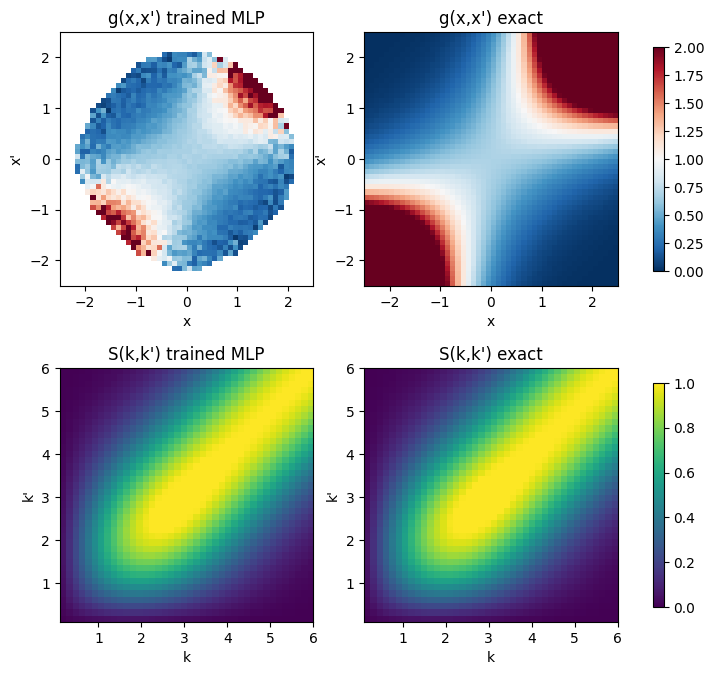

bulk |x|,|x'| < 1.5: max |g - exact| = nan, rms = nan
max |S - exact| = 0.010


In [17]:
wf_nn = TrainedWavefunction.from_result(psi, result, n_particles, n_dim=1, seed=1)
wf_nn.sample(n_chains=512, n_steps=1000, burn_in=100, thinning=4)
compare(wf_nn, "trained MLP")

## What this does and does not show

- **The reference is validated.** The sampled exact psi reproduces Sigma to 3e-3 and
  matches the analytic g and S, so the formulas and the estimators agree. The g error
  near the edge of the bulk window comes from few counts in steep, strongly bunched bins.
- **A good energy does not mean a good g.** The trained MLP reaches 2.5097 against
  2.5 (0.4% off), but sigma_E is still about 0.27, not 0, and its g(x, x') is visibly
  less bunched than the exact one: the off-diagonal corners are weaker. S(k, k') hides
  this, agreeing to about 1e-2. The energy is quadratic in the wavefunction error,
  while g is first order, so g is the sharper test. Train longer, or watch sigma_E,
  before trusting two-point functions.
- g(x, x') here is a smooth Gaussian correlation, with no correlation hole and no cusp.
  It tests whether the network learns pair structure at all, not short-range physics.
  The Calogero model in notebook 5 has the repulsive, algebraic case.
- The springs are attractive only, because the code squares `omega_interaction`.
- These are single-seed numbers without error bars.